# NASA Exoplanet Archive — pipeline analysis

Looks at the two tables produced by the pipeline:

`pscomppars_2026-08-04.csv`: raw PSCompPars download, one row per planet, transiting only
`NASAExoArchive_2026-08-21_aggregate.csv`: the same rows plus the derived phase-curve and observability columns


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plot_utils import paper_figure, paper_theme

RAW_FILE = "pscomppars_2026-08-04.csv"
AGG_FILE = "NASAExoArchive_2026-08-21_aggregate.csv"

raw = pd.read_csv(RAW_FILE, low_memory=False)
agg = pd.read_csv(AGG_FILE, low_memory=False)

print(f"raw       : {raw.shape[0]} planets x {raw.shape[1]} columns")
print(f"aggregate : {agg.shape[0]} planets x {agg.shape[1]} columns")
print(f"derived   : {agg.shape[1] - raw.shape[1]} new columns")

raw       : 4716 planets x 224 columns
aggregate : 4716 planets x 277 columns
derived   : 53 new columns


#### Downloader

In [2]:
raw

,pl_name,hostname,pl_letter,tic_id,sy_snum,sy_pnum,sy_mnum,cb_flag,discoverymethod,disc_year,...,sy_tmagerr2,sy_tmag_reflink,sy_icmag,sy_icmagerr1,sy_icmagerr2,sy_icmag_reflink,sy_kepmag,sy_kepmagerr1,sy_kepmagerr2,sy_kepmag_reflink
0,Kepler-1808 b,Kepler-1808,b,TIC 121215333,1,1,0,0,Transit,2021,...,-0.009500,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,15.230,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
1,Kepler-418 b,Kepler-418,b,TIC 377871791,1,2,0,0,Transit,2014,...,-0.007200,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,14.696,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
2,Kepler-249 d,Kepler-249,d,TIC 272942100,1,3,0,0,Transit,2014,...,-0.007328,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,15.234,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
3,Kepler-1408 b,Kepler-1408,b,TIC 123496782,1,1,0,0,Transit,2016,...,-0.006700,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12.003,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
4,Kepler-500 b,Kepler-500,b,TIC 271968263,1,1,0,0,Transit,2016,...,-0.009000,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,14.176,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4711,K2-122 b,K2-122,b,TIC 14635562,2,1,0,0,Transit,2017,...,-0.007295,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12.466,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
4712,TOI-654.01,TOI-654,b,TIC 35009898,1,1,0,0,Transit,2024,...,-0.007405,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
4713,Kepler-295 d,Kepler-295,d,TIC 164890864,1,3,0,0,Transit,2014,...,-0.006300,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,14.447,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
4714,Kepler-1689 b,Kepler-1689,b,TIC 137218786,1,1,0,0,Transit,2020,...,-0.006000,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,NaN,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,12.147,NaN,NaN,<a refstr=STASSUN_ET_AL__2019 href=https://ui....


In [3]:
key = ["pl_orbper", "pl_rade", "pl_bmasse", "pl_ratror", "pl_ratdor", "pl_orbsmax",
       "pl_orbeccen", "pl_tranmid", "pl_trandep", "pl_occdep", "pl_eqt",
       "st_teff", "st_rad", "st_mass", "sy_jmag", "sy_kmag", "sy_dist"]

completeness = pd.DataFrame({
    "present": raw[key].notna().sum(),
    "missing": raw[key].isna().sum(),
    "% missing": (100 * raw[key].isna().mean()).round(1),
})
completeness.sort_values("% missing", ascending=False)

,present,missing,% missing
pl_occdep,36,4680,99.2
pl_orbeccen,4067,649,13.8
pl_orbsmax,4355,361,7.7
pl_ratdor,4469,247,5.2
pl_trandep,4500,216,4.6
pl_eqt,4550,166,3.5
pl_ratror,4555,161,3.4
pl_bmasse,4692,24,0.5
sy_dist,4701,15,0.3
sy_jmag,4707,9,0.2


In [4]:
# pl_occdep is the only column that already holds a MEASURED occultation depth.
measured = raw[raw["pl_occdep"].notna()]
print(f"planets with a published occultation depth: {len(measured)} of {len(raw)}")
print(f"planets flagged as phase-curve detections (obm_flag): {int((raw.obm_flag == 1).sum())}")

planets with a published occultation depth: 36 of 4716
planets flagged as phase-curve detections (obm_flag): 29


### Custom Columns

In [5]:
new_cols = [c for c in agg.columns if c not in raw.columns]

groups = {
    "origin flags": [c for c in new_cols if c.endswith(("_derived", "_calculated")) or c in ("is_custom", "e_fitted", "ephem_same_ref")],
    "geometry":         [c for c in new_cols if c in ("a_over_r2", "pl_rprs2", "q", "RR_RP", "RR_RE", "delta_Na")],
    "temperatures":     [c for c in new_cols if c.startswith("pl_T")],
    "occultation depths": [c for c in new_cols if c.startswith("occdep")],
    "observability":    [c for c in new_cols if c in ("ESM", "TSM", "SNR_HST", "scale", "t0_n_err") or c.startswith(("noise_", "efficiency_"))],
}
for name, cols in groups.items():
    print(f"{name:20} ({len(cols):2}): {', '.join(cols)}\n")

origin flags         (12): is_custom, pl_rade_derived, pl_bmasse_derived, pl_ratror_derived, pl_ratdor_derived, pl_insol_derived, pl_orbincl_derived, pl_trandur_derived, ephem_same_ref, pl_bmasse_calculated, pl_rade_calculated, e_fitted

geometry             ( 6): a_over_r2, pl_rprs2, q, RR_RP, RR_RE, delta_Na

temperatures         ( 5): pl_Teq, pl_Teq_ecc, pl_Tsubst, pl_Trock, pl_Teq_err

occultation depths   (19): occdep_600nm_Trock, occdep_600nm_Teq, occdep_640nm_Trock, occdep_640nm_Teq, occdep_800nm_Trock, occdep_800nm_Teq, occdep_1400nm_Trock, occdep_1400nm_Teq, occdep_4000nm_Trock, occdep_4000nm_Teq, occdep_7500nm_Trock, occdep_7500nm_Teq, occdep_8000nm_Trock, occdep_8000nm_Teq, occdep_15000nm_Trock, occdep_15000nm_Teq, occdep_refl_A0p1, occdep_ESM, occdep_ESM_err

observability        (11): ESM, scale, TSM, efficiency_jmag, noise_jmag, efficiency_kmag, noise_kmag, efficiency_vmag, noise_vmag, SNR_HST, t0_n_err



#### How much of this is actually measured?

Three separate things can make a value non-published:

- `*_derived` — this pipeline computed it (e.g. `pl_ratdor` from `pl_orbsmax / st_rad`)
- `*_calculated` — the **archive** computed it from a mass–radius relation
- `e_fitted == False` — eccentricity was fixed at 0 by assumption, or quoted only as a bound

In [6]:
prov = pd.DataFrame({
    "n": {c.replace("_derived", ""): int(agg[c].sum()) for c in agg.columns if c.endswith("_derived")}
})
prov["% of planets"] = (100 * prov["n"] / len(agg)).round(1)
print("Values filled in by the pipeline:")
display(prov.sort_values("n", ascending=False))

print("\nValues the ARCHIVE calculated from a mass-radius relation:")
for c in [c for c in agg.columns if c.endswith("_calculated")]:
    print(f"  {c.replace('_calculated',''):12} {int(agg[c].sum()):5d}  ({100*agg[c].mean():.1f}%)")

Values filled in by the pipeline:


,n,% of planets
pl_orbincl,271,5.7
pl_ratdor,226,4.8
pl_insol,204,4.3
pl_ratror,160,3.4
pl_trandur,77,1.6
pl_rade,0,0.0
pl_bmasse,0,0.0



Values the ARCHIVE calculated from a mass-radius relation:
  pl_bmasse     2977  (63.1%)
  pl_rade          0  (0.0%)


In [7]:
# Eccentricity is the one that bites the tidal-heating work.
short = agg[agg["pl_orbper"] < 5]
print(f"planets with P < 5 d                     : {len(short)}")
print(f"  eccentricity actually fitted           : {int(short.e_fitted.sum())}  ({100*short.e_fitted.mean():.1f}%)")
print(f"  e present but NOT fitted (assumed/bound): {int((short.pl_orbeccen.notna() & ~short.e_fitted).sum())}")
print(f"  e missing entirely                     : {int(short.pl_orbeccen.isna().sum())}")

planets with P < 5 d                     : 1659
  eccentricity actually fitted           : 258  (15.6%)
  e present but NOT fitted (assumed/bound): 1137
  e missing entirely                     : 264


#### Sanity checks

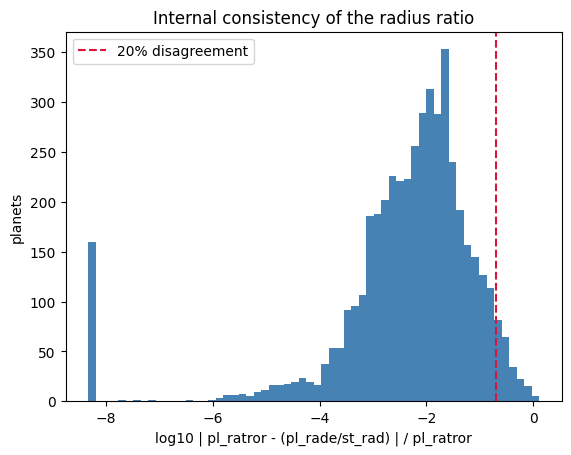

median disagreement : 0.80%
worse than 20%      : 193 planets


In [8]:
PAPER_MODE = False
# Is the published radius ratio consistent with the catalogue radii?
# A large disagreement means pl_ratror and (pl_rade, st_rad) came from different papers.
R_EARTH_IN_R_SUN = 0.0091678885
from_radii = R_EARTH_IN_R_SUN * agg["pl_rade"] / agg["st_rad"]
mismatch = ((agg["pl_ratror"] - from_radii) / agg["pl_ratror"]).abs()

fig, ax = plt.subplots()
ax.hist(np.log10(mismatch[mismatch > 0].dropna()), bins=60, color="steelblue")
ax.axvline(np.log10(0.20), color="crimson", ls="--", label="20% disagreement")
ax.set_xlabel("log10 | pl_ratror - (pl_rade/st_rad) | / pl_ratror")
ax.set_ylabel("planets")
ax.set_title("Internal consistency of the radius ratio")
ax.legend()
paper_figure("archive_radius_ratio_consistency", PAPER_MODE, fig=fig)
plt.show()

print(f"median disagreement : {mismatch.median():.2%}")
print(f"worse than 20%      : {int((mismatch > 0.20).sum())} planets")

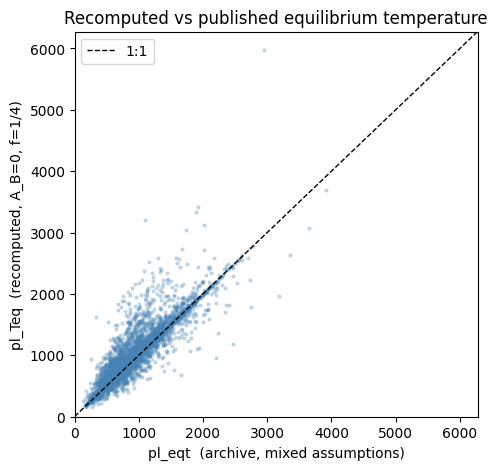

n = 4534   median ratio = 1.032   16-84 pct = 0.966 - 1.241
planets differing by more than 10%: 1873


In [9]:
PAPER_MODE = False
# Our pl_Teq vs the archive's own pl_eqt.
both = agg[agg["pl_Teq"].notna() & agg["pl_eqt"].notna()]

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(both["pl_eqt"], both["pl_Teq"], s=4, alpha=0.25, color="steelblue")
lims = [0, both[["pl_eqt", "pl_Teq"]].max().max() * 1.05]
ax.plot(lims, lims, "k--", lw=1, label="1:1")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("pl_eqt  (archive, mixed assumptions)")
ax.set_ylabel("pl_Teq  (recomputed, A_B=0, f=1/4)")
ax.set_title("Recomputed vs published equilibrium temperature")
ax.legend()
paper_figure("archive_teq_recomputed_vs_published", PAPER_MODE, fig=fig)
plt.show()

ratio = (both["pl_Teq"] / both["pl_eqt"])
print(f"n = {len(both)}   median ratio = {ratio.median():.3f}   16-84 pct = {ratio.quantile(0.16):.3f} - {ratio.quantile(0.84):.3f}")
print(f"planets differing by more than 10%: {int(((ratio - 1).abs() > 0.10).sum())}")

#### Hyper-illumination

/tmp/ipykernel_83830/729210504.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg["r2_over_R"] = 1.0 / agg["a_over_r2"]


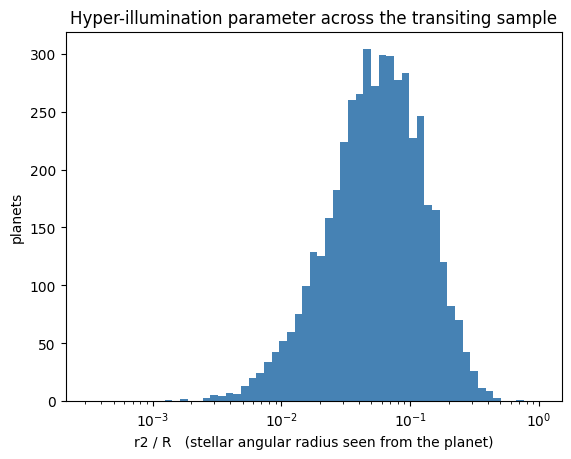

  r2/R > 0.1 : 1143 planets   (star subtends > 11 deg on the sky)
  r2/R > 0.2 :  229 planets   (star subtends > 23 deg on the sky)
  r2/R > 0.3 :   46 planets   (star subtends > 35 deg on the sky)
  r2/R > 0.5 :    2 planets   (star subtends > 60 deg on the sky)


In [10]:
PAPER_MODE = False
agg["r2_over_R"] = 1.0 / agg["a_over_r2"]

fig, ax = plt.subplots()
ax.hist(agg["r2_over_R"].dropna(), bins=np.logspace(-3.5, 0, 60), color="steelblue")
ax.set_xscale("log")
ax.set_xlabel("r2 / R   (stellar angular radius seen from the planet)")
ax.set_ylabel("planets")
ax.set_title("Hyper-illumination parameter across the transiting sample")
paper_figure("archive_hyperillumination_parameter", PAPER_MODE, fig=fig)
plt.show()

for thr in [0.1, 0.2, 0.3, 0.5]:
    n = int((agg["r2_over_R"] > thr).sum())
    print(f"  r2/R > {thr:.1f} : {n:4d} planets   (star subtends > {2*np.degrees(np.arcsin(min(thr,1))):.0f} deg on the sky)")

In [11]:
# The most hyper-illuminated transiting planets.
cols = ["pl_name", "r2_over_R", "a_over_r2", "pl_orbper", "pl_rade", "st_teff", "st_rad", "pl_Teq", "pl_Trock", "ESM"]
top = agg.nlargest(25, "r2_over_R")[cols]
top.round({"r2_over_R": 3, "a_over_r2": 2, "pl_orbper": 4, "pl_rade": 2, "st_rad": 3, "pl_Teq": 0, "pl_Trock": 0, "ESM": 1})

,pl_name,r2_over_R,a_over_r2,pl_orbper,pl_rade,st_teff,st_rad,pl_Teq,pl_Trock,ESM
3358,ZTF J1828+2308 b,1.193,0.84,0.1120,11.13,15900.0,0.013,12282.0,15695.0,NaN
62,ZTF J1230-2655 b,0.714,1.40,0.2360,13.79,10000.0,0.012,5976.0,7637.0,NaN
646,TOI-2431 b,0.481,2.08,0.2242,1.53,4109.0,0.651,2014.0,2574.0,26.0
3102,TOI-2260 b,0.451,2.22,0.3525,1.62,5534.0,0.940,2627.0,3357.0,8.6
4264,TOI-2109 b,0.441,2.27,0.6725,15.10,6540.0,1.698,3071.0,3924.0,195.2
1077,Kepler-1340 b,0.434,2.31,0.6650,1.55,6331.0,1.420,2581.0,3298.0,0.3
3348,K2-141 b,0.424,2.36,0.2803,1.51,4570.0,0.681,2134.0,2728.0,16.1
3343,KOI-1843.03,0.419,2.39,0.1769,0.61,3584.0,0.450,1839.0,2349.0,1.5
1324,K2-157 b,0.416,2.41,0.3653,0.94,5334.0,0.860,2432.0,3108.0,1.1
2905,Kepler-990 c,0.408,2.45,0.5384,1.53,5948.0,1.080,2486.0,3177.0,0.7


#### Rocky Planets around M dwarfs

In [12]:
m_dwarf_rocky = agg[(agg["st_teff"] < 4000) & (agg["pl_rade"] < 2.0) & (agg["pl_orbper"] < 10)].copy()
print(f"{len(m_dwarf_rocky)} planets with Teff < 4000 K, Rp < 2 R_earth, P < 10 d")

cols = ["pl_name", "pl_orbper", "pl_rade", "r2_over_R", "st_teff", "sy_kmag",
        "pl_Teq", "pl_Trock", "occdep_15000nm_Trock", "occdep_15000nm_Teq",
        "ESM", "occdep_ESM_err", "e_fitted", "pl_occdep"]
m_dwarf_rocky.nlargest(25, "ESM")[cols].round(
    {"pl_orbper": 3, "pl_rade": 2, "r2_over_R": 3, "st_teff": 0, "sy_kmag": 2,
     "pl_Teq": 0, "pl_Trock": 0, "occdep_15000nm_Trock": 1, "occdep_15000nm_Teq": 1,
     "ESM": 1, "occdep_ESM_err": 1})

187 planets with Teff < 4000 K, Rp < 2 R_earth, P < 10 d


,pl_name,pl_orbper,pl_rade,r2_over_R,st_teff,sy_kmag,pl_Teq,pl_Trock,occdep_15000nm_Trock,occdep_15000nm_Teq,ESM,occdep_ESM_err,e_fitted,pl_occdep
4316,LHS 3844 b,0.463,1.29,0.141,3080.0,9.15,816.0,1043.0,949.6,639.8,28.8,21.3,False,NaN
1409,TOI-6324 b,0.279,1.06,0.315,3247.0,8.69,1290.0,1648.0,476.8,341.1,24.1,24.2,False,NaN
2719,GJ 806 b,0.926,1.33,0.137,3600.0,6.53,942.0,1204.0,216.6,149.3,24.0,4.0,False,NaN
4693,GJ 486 b,1.467,1.29,0.088,3317.0,6.36,695.0,888.0,239.3,156.4,22.1,3.2,True,NaN
1830,TOI-6255 b,0.238,1.08,0.323,3421.0,8.07,1374.0,1756.0,317.4,228.4,21.9,24.3,False,NaN
400,GJ 367 b,0.322,0.74,0.299,3535.0,5.78,1370.0,1750.0,93.6,67.3,18.4,5.8,False,NaN
3140,GJ 1252 b,0.518,1.19,0.199,3458.0,7.92,1090.0,1393.0,253.3,178.0,16.5,17.0,False,NaN
4558,TOI-4552 b,0.301,1.11,0.237,3258.0,9.40,1122.0,1434.0,445.4,313.9,15.1,NaN,False,NaN
2545,TOI-1634 b,0.989,1.76,0.136,3550.0,8.60,945.0,1208.0,327.9,226.0,14.1,17.4,False,NaN
928,LTT 3780 b,0.768,1.32,0.148,3358.0,8.20,911.0,1164.0,266.7,182.9,13.5,12.1,False,NaN


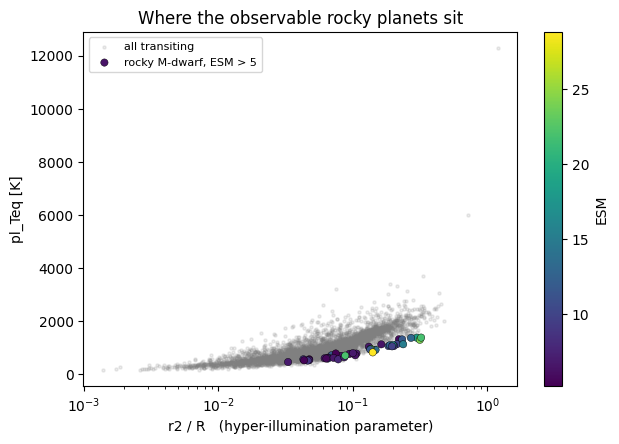

In [13]:
PAPER_MODE = False
# Where the good targets sit in the hyper-illumination / temperature plane.
fig, ax = plt.subplots(figsize=(7, 4.6))
sc = ax.scatter(agg["r2_over_R"], agg["pl_Teq"], s=5, alpha=0.15, color="grey", label="all transiting")
good = m_dwarf_rocky[m_dwarf_rocky["ESM"] > 5]
p = ax.scatter(good["r2_over_R"], good["pl_Teq"], s=28, c=good["ESM"], cmap="viridis", edgecolor="k", linewidth=0.3, label="rocky M-dwarf, ESM > 5")
plt.colorbar(p, ax=ax, label="ESM")
ax.set_xscale("log")
ax.set_xlabel("r2 / R   (hyper-illumination parameter)")
ax.set_ylabel("pl_Teq [K]")
ax.set_title("Where the observable rocky planets sit")
ax.legend(loc="upper left", fontsize=8)
paper_figure("archive_targets_hi_vs_temperature", PAPER_MODE, fig=fig)
plt.show()

#### Reference system — K2-141 b

In [14]:
waves = [600, 640, 800, 1400, 4000, 7500, 8000, 15000]
k2 = agg[agg["pl_name"].str.contains("K2-141", na=False)]
display(k2[["pl_name", "pl_orbper", "pl_rade", "pl_bmasse", "pl_ratror", "pl_ratdor",
            "a_over_r2", "r2_over_R", "pl_orbeccen", "e_fitted", "st_teff", "st_rad"]].round(5))

b = k2[k2["pl_name"] == "K2-141 b"].iloc[0]
print(f"\nTemperatures [K]:  Teq={b.pl_Teq:.0f}   Teq_ecc={b.pl_Teq_ecc:.0f}   Tsubstellar={b.pl_Tsubst:.0f}   Trock={b.pl_Trock:.0f}")
print(f"Hyper-illumination: r2/R = {b.r2_over_R:.3f}  (the star subtends {2*np.degrees(np.arcsin(b.r2_over_R)):.0f} deg from the planet)")
print(f"\nPredicted occultation depths [ppm]:")
for nm in waves:
    print(f"   {nm:>6} nm   hot(Trock) {b[f'occdep_{nm}nm_Trock']:8.1f}   cold(Teq) {b[f'occdep_{nm}nm_Teq']:8.1f}")

,pl_name,pl_orbper,pl_rade,pl_bmasse,pl_ratror,pl_ratdor,a_over_r2,r2_over_R,pl_orbeccen,e_fitted,st_teff,st_rad
674,K2-141 c,7.74850,7.00,8.00,0.09400,21.590,21.56637,0.04637,0.092,False,4570.0,0.681
3348,K2-141 b,0.28032,1.51,4.97,0.02088,2.292,2.35872,0.42396,0.000,False,4570.0,0.681



Temperatures [K]:  Teq=2134   Teq_ecc=2104   Tsubstellar=3019   Trock=2728
Hyper-illumination: r2/R = 0.424  (the star subtends 50 deg from the planet)

Predicted occultation depths [ppm]:
      600 nm   hot(Trock)     12.5   cold(Teq)      1.1
      640 nm   hot(Trock)     15.6   cold(Teq)      1.6
      800 nm   hot(Trock)     30.0   cold(Teq)      4.8
     1400 nm   hot(Trock)     87.4   cold(Teq)     30.2
     4000 nm   hot(Trock)    190.6   cold(Teq)    118.8
     7500 nm   hot(Trock)    222.9   cold(Teq)    156.1
     8000 nm   hot(Trock)    225.2   cold(Teq)    159.0
    15000 nm   hot(Trock)    241.6   cold(Teq)    179.5


Reference occ depth (Spitzer): 142 ppm.

pl_ratdor is not equal to a_over_r2, since they were sourced from different papers (Malavolta et al. 2018 vs. Bonomo et al. 2023).